# 🛰️ FloodShield AI — Model 4B: Flood Segmentation with U-Net (Sen1Floods11)

**Goal:** Train a proper deep learning segmentation model (U-Net) to detect flood water in Sentinel-1 SAR imagery — more accurate and robust than the simple thresholding used in Model 4A.

**Dataset:** [Sen1Floods11](https://github.com/cloudtostreet/Sen1Floods11) (Bonafilia et al., CVPR 2020 Workshops) — a public, hand-labeled dataset:
- 446 hand-labeled 512×512 chips of Sentinel-1 SAR imagery
- Covers 11 real flood events across 6 continents
- Free, public Google Cloud Storage bucket — **no download form, no login needed**, just `gsutil`

We don't need to build this dataset ourselves — it's already publicly available and designed exactly for this task. This notebook downloads it directly.

### How to run:
1. Runtime → Change runtime type → **GPU**
2. Runtime → Run all
3. Training on ~446 chips takes roughly 15–30 minutes on a Colab GPU


## 1️⃣ Setup

In [11]:
!pip install rasterio tensorflow scikit-learn matplotlib -q

from google.colab import drive
drive.mount('/content/drive')

import tensorflow as tf
print("GPU available:", tf.config.list_physical_devices('GPU'))


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2️⃣ Download Sen1Floods11 (Hand-Labeled Flood Chips Only)

We only download the **hand-labeled flood-water subset** (S1Hand = Sentinel-1 imagery, LabelHand = ground-truth flood masks) — not the full 14 GB dataset, since we just need the labeled training chips.


In [12]:
import os

DATA_DIR = '/content/drive/MyDrive/FloodShieldAI/data/sen1floods11'
os.makedirs(f'{DATA_DIR}/S1Hand', exist_ok=True)
os.makedirs(f'{DATA_DIR}/LabelHand', exist_ok=True)

# Public bucket -- no authentication needed for read access
!gsutil -m rsync -r gs://sen1floods11/v1.1/data/flood_events/HandLabeled/S1Hand {DATA_DIR}/S1Hand
!gsutil -m rsync -r gs://sen1floods11/v1.1/data/flood_events/HandLabeled/LabelHand {DATA_DIR}/LabelHand

s1_files = sorted(os.listdir(f'{DATA_DIR}/S1Hand'))
label_files = sorted(os.listdir(f'{DATA_DIR}/LabelHand'))
print(f"Downloaded {len(s1_files)} SAR chips and {len(label_files)} label chips")


Google recommends using Gcloud storage CLI (https://docs.cloud.google.com/storage/docs/discover-object-storage-gcloud) instead of gsutil. Please refer to migration guide (https://docs.cloud.google.com/storage/docs/gsutil-transition-to-gcloud) for assistance.

both the source and destination. Your crcmod installation isn't using the
module's C extension, so checksumming will run very slowly. If this is your
first rsync since updating gsutil, this rsync can take significantly longer than
usual. For help installing the extension, please see "gsutil help crcmod".

Building synchronization state...
Starting synchronization...
Copying gs://sen1floods11/v1.1/data/flood_events/HandLabeled/S1Hand/Bolivia_312675_S1Hand.tif...
Copying gs://sen1floods11/v1.1/data/flood_events/HandLabeled/S1Hand/Bolivia_233925_S1Hand.tif...
Copying gs://sen1floods11/v1.1/data/flood_events/HandLabeled/S1Hand/Bolivia_242570_S1Hand.tif...
Copying gs://sen1floods11/v1.1/data/flood_events/HandLabeled/S1Hand/Bolivia_2301

## 3️⃣ Load & Preprocess GeoTIFF Chips

Each chip: Sentinel-1 SAR (VV + VH bands) + a matching ground-truth mask (0 = no water, 1 = water, -1 = invalid/no-data).


In [13]:
import rasterio
import numpy as np

def load_chip(s1_path, label_path):
    with rasterio.open(s1_path) as src:
        img = src.read()  # shape (2, H, W) -- VV, VH
    with rasterio.open(label_path) as src:
        label = src.read(1)  # shape (H, W)
    return img, label

def normalize_sar(img):
    # SAR values are in dB, typically -50 to 0 -- clip and scale to 0-1
    img = np.clip(img, -50, 0)
    img = (img + 50) / 50.0
    return img

s1_paths = [f'{DATA_DIR}/S1Hand/{f}' for f in s1_files]
label_paths = [f'{DATA_DIR}/LabelHand/{f}' for f in label_files]

print("Sample chip check:")
img, label = load_chip(s1_paths[0], label_paths[0])
print("SAR image shape:", img.shape, "| Label shape:", label.shape)
print("Label unique values:", np.unique(label))


Sample chip check:
SAR image shape: (2, 512, 512) | Label shape: (512, 512)
Label unique values: [-1  0  1]


## 4️⃣ Build Training Arrays

Chips are 512×512 — we resize to 256×256 to keep training fast and memory-friendly on a Colab GPU.


In [14]:
from tensorflow.image import resize as tf_resize

IMG_SIZE = 256

X_data, y_data = [], []

for s1_path, label_path in zip(s1_paths, label_paths):
    try:
        img, label = load_chip(s1_path, label_path)
        img = normalize_sar(img)                      # (2, H, W)
        img = np.transpose(img, (1, 2, 0))             # (H, W, 2)

        # skip chips that are mostly invalid (-1) labels
        valid_ratio = np.mean(label != -1)
        if valid_ratio < 0.5:
            continue

        label_clean = np.where(label == -1, 0, label)  # treat invalid as no-water for training

        img_resized = tf_resize(img, (IMG_SIZE, IMG_SIZE)).numpy()
        label_resized = tf_resize(label_clean[..., np.newaxis], (IMG_SIZE, IMG_SIZE), method='nearest').numpy()

        X_data.append(img_resized)
        y_data.append(label_resized)
    except Exception as e:
        continue

X_data = np.array(X_data, dtype=np.float32)
y_data = np.array(y_data, dtype=np.float32)

print("X_data:", X_data.shape, "| y_data:", y_data.shape)
print("Water pixel ratio:", y_data.mean())


X_data: (408, 256, 256, 2) | y_data: (408, 256, 256, 1)
Water pixel ratio: 0.09660826


## 5️⃣ Train/Validation/Test Split

In [15]:
from sklearn.model_selection import train_test_split

X_train, X_temp, y_train, y_temp = train_test_split(X_data, y_data, test_size=0.3, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42)

print("Train:", X_train.shape, "Val:", X_val.shape, "Test:", X_test.shape)


Train: (285, 256, 256, 2) Val: (61, 256, 256, 2) Test: (62, 256, 256, 2)


## 6️⃣ Build U-Net Model

In [16]:
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, UpSampling2D, concatenate, BatchNormalization, Dropout

def conv_block(x, filters):
    x = Conv2D(filters, 3, padding='same', activation='relu')(x)
    x = BatchNormalization()(x)
    x = Conv2D(filters, 3, padding='same', activation='relu')(x)
    x = BatchNormalization()(x)
    return x

def build_unet(input_shape=(256,256,2)):
    inputs = Input(input_shape)

    c1 = conv_block(inputs, 32)
    p1 = MaxPooling2D()(c1)

    c2 = conv_block(p1, 64)
    p2 = MaxPooling2D()(c2)

    c3 = conv_block(p2, 128)
    p3 = MaxPooling2D()(c3)

    c4 = conv_block(p3, 256)
    p4 = MaxPooling2D()(c4)

    bn = conv_block(p4, 512)
    bn = Dropout(0.3)(bn)

    u4 = UpSampling2D()(bn)
    u4 = concatenate([u4, c4])
    c5 = conv_block(u4, 256)

    u3 = UpSampling2D()(c5)
    u3 = concatenate([u3, c3])
    c6 = conv_block(u3, 128)

    u2 = UpSampling2D()(c6)
    u2 = concatenate([u2, c2])
    c7 = conv_block(u2, 64)

    u1 = UpSampling2D()(c7)
    u1 = concatenate([u1, c1])
    c8 = conv_block(u1, 32)

    outputs = Conv2D(1, 1, activation='sigmoid')(c8)

    return Model(inputs, outputs)

unet_model = build_unet()
unet_model.summary()


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 256, 256,  │          0 │ -                 │
│ (InputLayer)        │ 2)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_19 (Conv2D)  │ (None, 256, 256,  │        608 │ input_layer_1[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 256, 256,  │        128 │ conv2d_19[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_20 (Conv2D)  │ (None, 256, 256,  │      9,248 │ batch_normalizat… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 256, 256,  │        128 │ conv2d_20[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_4     │ (None, 128, 128,  │          0 │ batch_normalizat… │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_21 (Conv2D)  │ (None, 128, 128,  │     18,496 │ max_pooling2d_4[… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 128,  │        256 │ conv2d_21[0][0]   │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_22 (Conv2D)  │ (None, 128, 128,  │     36,928 │ batch_normalizat… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 128,  │        256 │ conv2d_22[0][0]   │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_5     │ (None, 64, 64,    │          0 │ batch_normalizat… │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_23 (Conv2D)  │ (None, 64, 64,    │     73,856 │ max_pooling2d_5[… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │        512 │ conv2d_23[0][0]   │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_24 (Conv2D)  │ (None, 64, 64,    │    147,584 │ batch_normalizat… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │        512 │ conv2d_24[0][0]   │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_6     │ (None, 32, 32,    │          0 │ batch_normalizat… │
│ (MaxPooling2D)      │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_25 (Conv2D)  │ (None, 32, 32,    │    295,168 │ max_pooling2d_6[

 Total params: 7,858,145 (29.98 MB)

 Trainable params: 7,852,257 (29.95 MB)

 Non-trainable params: 5,888 (23.00 KB)

## 7️⃣ Compile & Train

In [17]:
def iou_metric(y_true, y_pred, smooth=1e-6):
    y_pred = tf.cast(y_pred > 0.5, tf.float32)
    intersection = tf.reduce_sum(y_true * y_pred)
    union = tf.reduce_sum(y_true) + tf.reduce_sum(y_pred) - intersection
    return (intersection + smooth) / (union + smooth)

unet_model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy', iou_metric]
)

from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

callbacks = [
    EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=5)
]

history = unet_model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=40,
    batch_size=8,
    callbacks=callbacks,
    verbose=1
)


Epoch 1/40
36/36 ━━━━━━━━━━━━━━━━━━━━ 48s 632ms/step - accuracy: 0.8739 - iou_metric: 0.0154 - loss: nan - val_accuracy: 0.9090 - val_iou_metric: 3.3319e-11 - val_loss: nan - learning_rate: 0.0010
Epoch 2/40
36/36 ━━━━━━━━━━━━━━━━━━━━ 7s 198ms/step - accuracy: 0.9065 - iou_metric: 3.1219e-11 - loss: nan - val_accuracy: 0.9090 - val_iou_metric: 3.3319e-11 - val_loss: nan - learning_rate: 0.0010
Epoch 3/40
36/36 ━━━━━━━━━━━━━━━━━━━━ 7s 194ms/step - accuracy: 0.9065 - iou_metric: 2.9334e-11 - loss: nan - val_accuracy: 0.9090 - val_iou_metric: 3.3319e-11 - val_loss: nan - learning_rate: 0.0010
Epoch 4/40
36/36 ━━━━━━━━━━━━━━━━━━━━ 7s 196ms/step - accuracy: 0.9065 - iou_metric: 3.9287e-11 - loss: nan - val_accuracy: 0.9090 - val_iou_metric: 3.3319e-11 - val_loss: nan - learning_rate: 0.0010
Epoch 5/40
36/36 ━━━━━━━━━━━━━━━━━━━━ 7s 193ms/step - accuracy: 0.9065 - iou_metric: 3.2640e-11 - loss: nan - val_accuracy: 0.9090 - val_iou_metric: 3.3319e-11 - val_loss: nan - learning_rate: 0.0010
Epo

## 8️⃣ Evaluate on Test Set

Test Accuracy: 0.8838
Test IoU (Intersection over Union): 0.0000


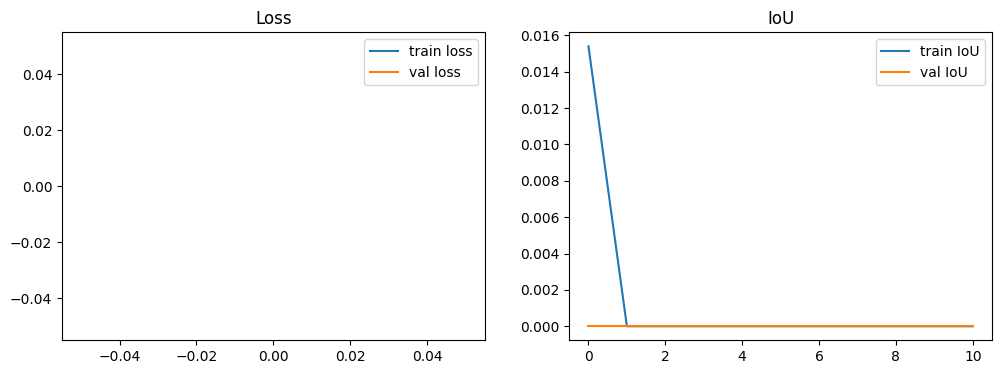

In [18]:
test_loss, test_acc, test_iou = unet_model.evaluate(X_test, y_test, verbose=0)
print(f"Test Accuracy: {test_acc:.4f}")
print(f"Test IoU (Intersection over Union): {test_iou:.4f}")

import matplotlib.pyplot as plt

plt.figure(figsize=(12,4))
plt.subplot(1,2,1)
plt.plot(history.history['loss'], label='train loss')
plt.plot(history.history['val_loss'], label='val loss')
plt.legend(); plt.title('Loss')

plt.subplot(1,2,2)
plt.plot(history.history['iou_metric'], label='train IoU')
plt.plot(history.history['val_iou_metric'], label='val IoU')
plt.legend(); plt.title('IoU')
plt.show()


## 9️⃣ Visualize Predictions

1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step


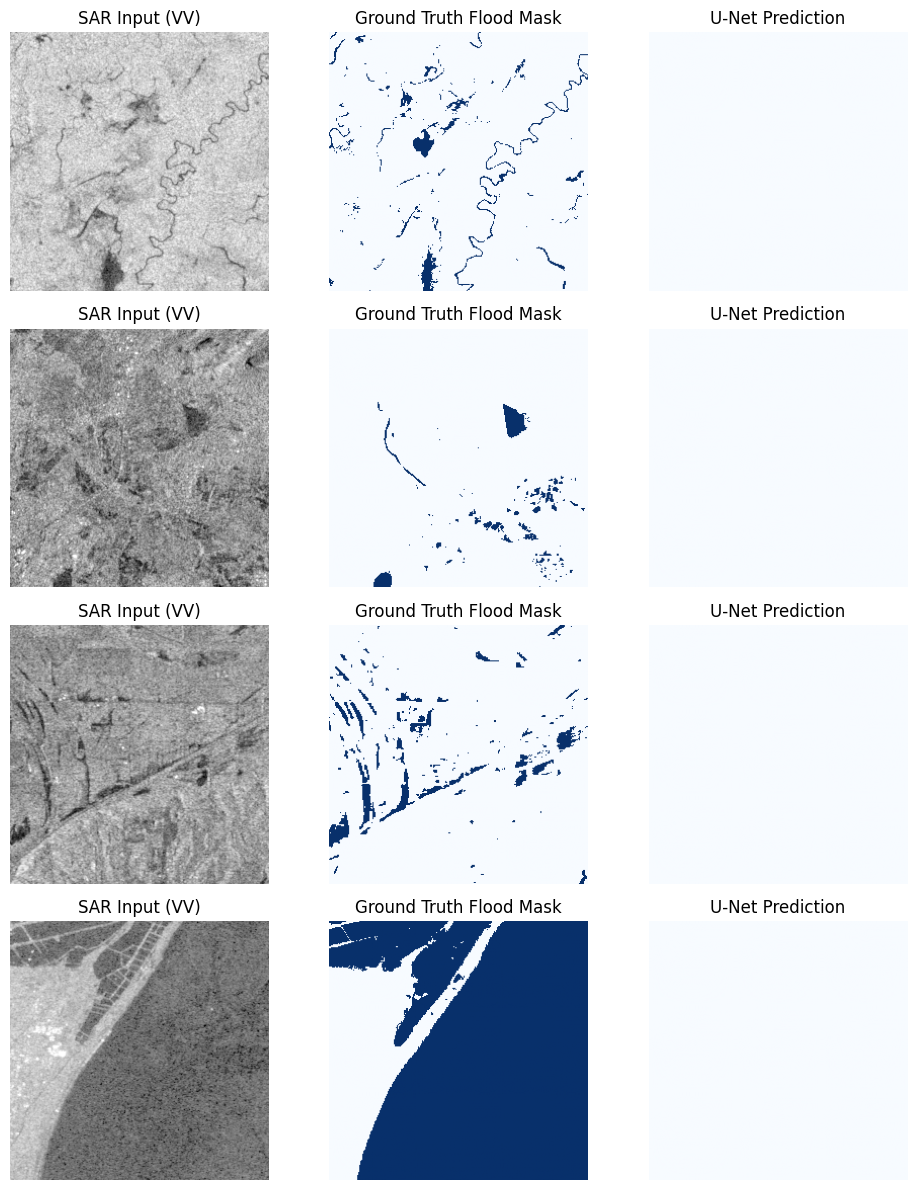

In [19]:
n_show = 4
preds = unet_model.predict(X_test[:n_show])

fig, axes = plt.subplots(n_show, 3, figsize=(10, 3*n_show))
for i in range(n_show):
    axes[i,0].imshow(X_test[i][:,:,0], cmap='gray')
    axes[i,0].set_title('SAR Input (VV)')
    axes[i,1].imshow(y_test[i,:,:,0], cmap='Blues')
    axes[i,1].set_title('Ground Truth Flood Mask')
    axes[i,2].imshow(preds[i,:,:,0] > 0.5, cmap='Blues')
    axes[i,2].set_title('U-Net Prediction')
    for ax in axes[i]:
        ax.axis('off')
plt.tight_layout()
plt.show()


## 🔟 Save Model

In [20]:
import os

SAVE_DIR = '/content/drive/MyDrive/FloodShieldAI/models'
os.makedirs(SAVE_DIR, exist_ok=True)

unet_model.save(f'{SAVE_DIR}/flood_segmentation_unet.keras')
print(f"✅ Saved to: {SAVE_DIR}/flood_segmentation_unet.keras")


✅ Saved to: /content/drive/MyDrive/FloodShieldAI/models/flood_segmentation_unet.keras


---
## ✅ What this notebook produces
- A trained U-Net that segments flood water from Sentinel-1 SAR imagery, pixel by pixel
- IoU (Intersection over Union) — the standard metric for segmentation quality
- Trained on a real, peer-reviewed, publicly available dataset (Sen1Floods11 — CVPR 2020 Workshops)

## How this connects to Model 4A
Model 4A (Google Earth Engine) pulls fresh Sentinel-1 imagery for any district/date in Bangladesh.
This U-Net model can replace the simple thresholding step in Model 4A with a proper learned segmentation — apply `unet_model.predict()` to a new SAR chip instead of `.lt(WATER_THRESHOLD)`, for more accurate, noise-robust flood extent detection.

## Honest note for the pitch
Sen1Floods11 was collected globally (not specifically Bangladesh) — it gives the model a strong general understanding of what flood water looks like in SAR imagery, but ideally should be fine-tuned or validated further with Bangladesh-specific labeled data before full production deployment.
